In [20]:
import pandas as pd
import json
import re
import os
import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoTokenizer
from datasets import Dataset, DatasetDict, Features, Value, Sequence
from sklearn.model_selection import train_test_split

In [21]:
# Global variables for configuration
CONFIG = {
    "search_csv": "search_bol.csv",
    "scraped_jsonl": "jsons/scraped_content.jsonl",
    "output_dir": "dataset",
    "max_tokens": 7000,
    "tokenizer_name": "meta-llama/Llama-3.1-8B-Instruct",
}

In [22]:
def load_search_data(file_path=None):
    """
    Load and process the search_bol.csv file containing product features
    """
    file_path = file_path or CONFIG["search_csv"]
    print(f"Loading search data from: {file_path}")
    
    # Load the CSV
    search_df = pd.read_csv(file_path)
    
    # Extract domain from search_url
    search_df['domain'] = search_df['search_url'].apply(
        lambda x: x.split('/')[2] if pd.notnull(x) else 'Unknown'
    )
    
    # Print summary statistics
    print(f"✅ Loaded {len(search_df)} product features")
    print(f"📊 Number of unique URLs: {search_df['search_url'].nunique()}")
    print(f"📊 Number of unique product IDs: {search_df['product_id'].nunique()}")
    print(f"📊 Number of unique taxonomy classes: {search_df['taxonomy_class_id'].nunique()}")
    
    # Show a sample of the data
    print("\n📋 Sample of search data:")
    display_sample = search_df.head(3)
    print(display_sample)
    
    return search_df

# Step 1: Load search data
search_df = load_search_data()

Loading search data from: search_bol.csv
✅ Loaded 187235 product features
📊 Number of unique URLs: 25304
📊 Number of unique product IDs: 17845
📊 Number of unique taxonomy classes: 678

📋 Sample of search data:
   product_id  taxonomy_class_id                                      text  \
0     7729940              77295             Aantal stuks in verpakking: 2   
1     7729370              72727  Maximale turboklokfrequentie: 2321 MHz     
2     7729370              72727                  Stream Processors: 768     

                                          search_url               domain  
0  https://rozetka.pl/439232396/p439232396/?srslt...           rozetka.pl  
1  https://www.informatique.nl/223115/asrock-rx64...  www.informatique.nl  
2  https://www.informatique.nl/223115/asrock-rx64...  www.informatique.nl  


In [23]:
def load_scraped_content(file_path=None):
    """
    Load the scraped_content.jsonl file containing webpage content
    """
    file_path = file_path or CONFIG["scraped_jsonl"]
    print(f"Loading scraped content from: {file_path}")
    
    # Load the JSONL file
    scraped_records = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            try:
                data = json.loads(line.strip())
                # Extract the domain and nested content
                for domain, content_data in data.items():
                    scraped_records.append({
                        "domain": domain,
                        "url": content_data.get("url", ""),
                        "content": content_data.get("content", ""),
                        "title": content_data.get("title", ""),
                        "timestamp": content_data.get("timestamp", "")
                    })
            except json.JSONDecodeError as e:
                print(f"⚠️ Error parsing line {i}: {e}")
                continue
    
    # Convert to DataFrame
    scraped_df = pd.DataFrame(scraped_records)
    
    # Print summary statistics
    print(f"✅ Loaded {len(scraped_df)} scraped content records")
    print(f"📊 Number of unique URLs: {scraped_df['url'].nunique()}")
    print(f"📊 Number of unique domains: {scraped_df['domain'].nunique()}")
    
    # Show content length statistics
    content_lengths = scraped_df['content'].apply(lambda x: len(x) if isinstance(x, str) else 0)
    print(f"📊 Content length statistics:")
    print(f"   - Min: {content_lengths.min()} characters")
    print(f"   - Max: {content_lengths.max()} characters")
    print(f"   - Average: {content_lengths.mean():.2f} characters")
    
    # Show a sample of the data (just first 100 chars of content)
    print("\n📋 Sample of scraped content:")
    sample_df = scraped_df.head(3).copy()
    sample_df['content'] = sample_df['content'].apply(
        lambda x: (x[:100] + '...') if isinstance(x, str) and len(x) > 100 else x
    )
    print(sample_df[['domain', 'url', 'title', 'content']])
    
    return scraped_df

# Step 2: Load scraped content
scraped_df = load_scraped_content()

Loading scraped content from: jsons/scraped_content.jsonl
✅ Loaded 23249 scraped content records
📊 Number of unique URLs: 23249
📊 Number of unique domains: 2060
📊 Content length statistics:
   - Min: 1 characters
   - Max: 10852401 characters
   - Average: 10382.15 characters

📋 Sample of scraped content:
              domain                                                url  \
0      www.osram.com  https://www.osram.com/ecat/STARTERcable%201200...   
1      trendform.com  https://trendform.com/inten/Card-holder-HANG-L...   
2  starboardtech.com  https://starboardtech.com/products/gedore-2823...   

                                               title  \
0       STARTERcable 1200A OSC500 | OSRAM Automotive   
1          Card holder HANG LOOSE set of 3  | TF5484   
2  Gedore 2823705 GEDORE i-BOXX 72 empty — starbo...   

                                             content  
0                         Please activate JavaScr...  
1              To be able to use the full range o...  
2 

In [24]:
def normalize_urls(search_df, scraped_df):
    """
    Normalize URLs in both datasets to improve matching
    """
    print("Normalizing URLs for better matching...")
    
    def normalize_url(url):
        """Normalize URLs by removing common variations"""
        if not isinstance(url, str):
            return ""
        # Convert to lowercase
        url = url.lower()
        # Remove http:// or https:// prefixes
        url = re.sub(r'^https?://', '', url)
        # Remove trailing slashes
        url = re.sub(r'/$', '', url)
        # Remove common query parameters
        url = re.sub(r'\?.*$', '', url)
        # Remove common fragments
        url = re.sub(r'#.*$', '', url)
        return url
    
    # Create normalized versions for matching
    search_df['normalized_url'] = search_df['search_url'].apply(normalize_url)
    scraped_df['normalized_url'] = scraped_df['url'].apply(normalize_url)
    
    # Analyze the results of normalization
    search_urls = set(search_df['normalized_url'])
    scraped_urls = set(scraped_df['normalized_url'])
    common_urls = search_urls.intersection(scraped_urls)
    
    print(f"📊 After URL normalization:")
    print(f"   - Search dataset: {len(search_urls)} unique normalized URLs")
    print(f"   - Scraped content: {len(scraped_urls)} unique normalized URLs")
    print(f"   - Common URLs: {len(common_urls)} ({(len(common_urls)/len(search_urls)*100):.2f}% of search URLs)")
    
    # Show example of URL normalization
    print("\n📋 Example of URL normalization:")
    sample_urls = search_df['search_url'].sample(min(3, len(search_df))).tolist()
    for url in sample_urls:
        print(f"Original:   {url}")
        print(f"Normalized: {normalize_url(url)}")
        print()
    
    return search_df, scraped_df, common_urls

# Step 3: Normalize URLs
search_df, scraped_df, common_urls = normalize_urls(search_df, scraped_df)

Normalizing URLs for better matching...
📊 After URL normalization:
   - Search dataset: 24809 unique normalized URLs
   - Scraped content: 22804 unique normalized URLs
   - Common URLs: 22804 (91.92% of search URLs)

📋 Example of URL normalization:
Original:   https://www.wasserman.eu/en/p/picture-velvet-green-1-piece-vertical-size-40x60-807869?srsltid=AfmBOop9jRM32ctNgd7ZAjJwEzJaLVnXE0YfB0m5uS9PRNaDkyZmuMrz
Normalized: www.wasserman.eu/en/p/picture-velvet-green-1-piece-vertical-size-40x60-807869

Original:   https://www.discountlight.com/be_nl/noxion-led-waterdichte-montagebalk-poseidon-v3-0-30w-3900-4200lm-830-865-cct-120cm-doorvoerbedrading-5x2-5mm2-dali-dimbaar-8719157046480
Normalized: www.discountlight.com/be_nl/noxion-led-waterdichte-montagebalk-poseidon-v3-0-30w-3900-4200lm-830-865-cct-120cm-doorvoerbedrading-5x2-5mm2-dali-dimbaar-8719157046480

Original:   https://www.vidaxl.nl/e/vidaxl-sta-op-massagestoel-verstelbaar-kunstleer-cremekleurig/8721012177604.html
Normalized: www.v

In [25]:
def match_features_with_content(search_df, scraped_df):
    """
    Match product features with scraped content using normalized URLs
    """
    print("Matching product features with scraped content...")
    
    # Create a lookup dictionary for faster matching
    normalized_url_to_scraped = {
        normalized_url: row for normalized_url, row in 
        zip(scraped_df['normalized_url'], scraped_df.to_dict('records'))
    }
    
    # Initialize container for matched features
    url_features = {}
    
    # Group features from search_df by normalized URL
    for normalized_url, group in search_df.groupby('normalized_url'):
        # Only process URLs that have a direct match in the scraped data
        if normalized_url in normalized_url_to_scraped:
            scraped_row = normalized_url_to_scraped[normalized_url]
            scraped_url = scraped_row['url']
            
            # Take the product ID and taxonomy from the first entry in the group
            first_row = group.iloc[0]
            product_id = first_row['product_id']
            taxonomy_id = first_row['taxonomy_class_id']
            
            # Initialize the features container for this URL if it doesn't exist
            if scraped_url not in url_features:
                url_features[scraped_url] = {
                    "features": [],
                    "product_id": product_id,
                    "taxonomy_class_id": taxonomy_id,
                    "search_url": first_row['search_url']
                }
            
            # Add all features from this URL's group
            for _, row in group.iterrows():
                feature_text = row['text']
                
                # Extract feature name and value
                if ':' in feature_text:
                    parts = feature_text.split(':', 1)
                    feature_name = parts[0].strip()
                    feature_value = parts[1].strip()
                    
                    url_features[scraped_url]["features"].append({
                        "key": feature_name,
                        "value": feature_value
                    })
                else:
                    # Handle cases without colon separator
                    url_features[scraped_url]["features"].append({
                        "key": "description",
                        "value": feature_text.strip()
                    })
    
    # Print summary statistics
    print(f"Matched {len(url_features)} URLs with features and content")
    
    # Analyze feature counts per URL
    feature_counts = [len(data["features"]) for data in url_features.values()]
    if feature_counts:
        print(f"📊 Features per URL statistics:")
        print(f"   - Min: {min(feature_counts)} features")
        print(f"   - Max: {max(feature_counts)} features")
        print(f"   - Average: {sum(feature_counts)/len(feature_counts):.2f} features")
    
    # Show sample of a matched product with its features
    if url_features:
        print("\n📋 Sample of matched product with features:")
        sample_url = next(iter(url_features))
        sample_data = url_features[sample_url]
        print(f"Product ID: {sample_data['product_id']}")
        print(f"Taxonomy ID: {sample_data['taxonomy_class_id']}")
        print(f"URL: {sample_url}")
        print(f"Features ({len(sample_data['features'])}):")
        for i, feature in enumerate(sample_data['features'][:5]):  # Show first 5 features
            print(f"   {i+1}. {feature['key']}: {feature['value']}")
        if len(sample_data['features']) > 5:
            print(f"   ... and {len(sample_data['features'])-5} more features")
    
    return url_features

# Step 4: Match features with content
url_features = match_features_with_content(search_df, scraped_df)

Matching product features with scraped content...
Matched 22804 URLs with features and content
📊 Features per URL statistics:
   - Min: 1 features
   - Max: 315 features
   - Average: 7.70 features

📋 Sample of matched product with features:
Product ID: 7738314
Taxonomy ID: 73125
URL: https://4office.be/nl/p/function-wall-module-5-36010
Features (4):
   1. Aantal stuks in verpakking: 1
   2. Product hoogte: 57 mm
   3. Product lengte: 337 mm
   4. Product breedte: 57 mm


Tokenizing and truncating content (max: 7000 tokens)...
Loading tokenizer: meta-llama/Llama-3.1-8B-Instruct


Token indices sequence length is longer than the specified maximum sequence length for this model (147185 > 131072). Running this sequence through the model will result in indexing errors


✅ Processed 22804 products
📊 Truncated 664 products (2.91% of total)
📊 Final dataset size: 14764 products (after filtering for ≥3 features)

📊 Token length statistics (after truncation):
   - Min: 2 tokens
   - Max: 7000 tokens
   - Average: 2814.78 tokens

📊 Original token length statistics (before truncation):
   - Min: 2 tokens
   - Max: 147185 tokens
   - Average: 2877.50 tokens


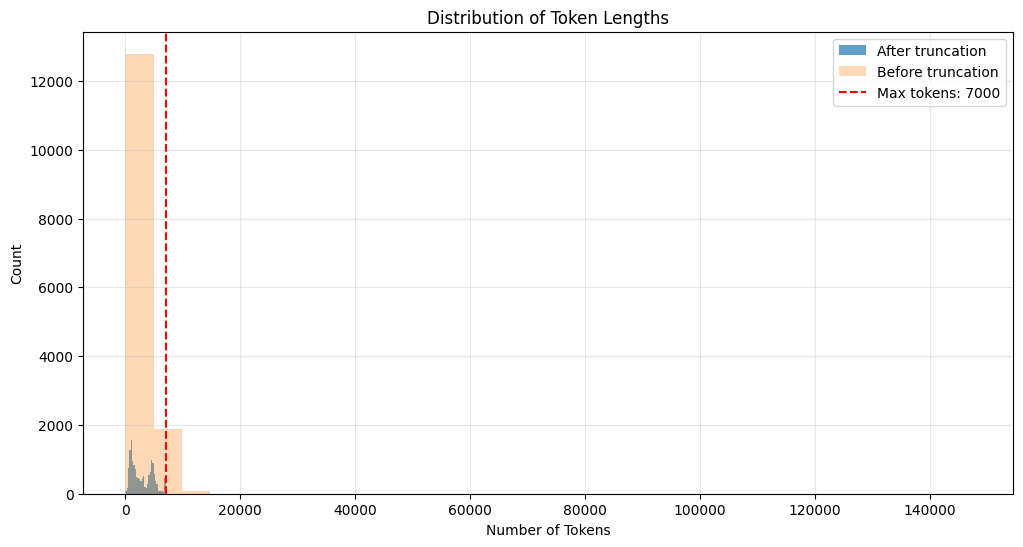

In [26]:
def tokenize_and_truncate_content(url_features, scraped_df, tokenizer_name=None, max_tokens=None):
    """
    Tokenize and truncate content to fit within token limit
    """
    tokenizer_name = tokenizer_name or CONFIG["tokenizer_name"]
    max_tokens = max_tokens or CONFIG["max_tokens"]
    
    print(f"Tokenizing and truncating content (max: {max_tokens} tokens)...")
    
    # Load the tokenizer
    print(f"Loading tokenizer: {tokenizer_name}")
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)
    
    # Prepare the final dataset with truncated content
    merged_data = []
    truncated_count = 0
    total_count = 0
    
    # Process each URL with matched features
    for url, data in url_features.items():
        total_count += 1
        features = data["features"]
            
        # Find content for this URL in scraped_df
        product_content = scraped_df[scraped_df['url'] == url]
        
        if not product_content.empty:
            content = product_content.iloc[0]['content']
            title = product_content.iloc[0]['title']
            timestamp = product_content.iloc[0]['timestamp']
            
            # Use the tokenizer to properly truncate the content
            if content:
                # Tokenize the content
                encoded = tokenizer.encode(content)
                original_token_length = len(encoded)
                
                # Check if truncation is needed
                if original_token_length > max_tokens:
                    # Truncate to the specified length and decode back to text
                    truncated_encoded = encoded[:max_tokens]
                    content = tokenizer.decode(truncated_encoded, skip_special_tokens=True)
                    truncated_count += 1
                
                token_length = min(original_token_length, max_tokens)
            else:
                token_length = 0
                original_token_length = 0
            
            # Only include items with at least 3 features
            if len(features) >= 3:
                merged_data.append({
                    "url": url,
                    "title": title,
                    "content": content,
                    "paragraphs": [{"text": content}],
                    "labels": features,
                    "feature_count": len(features),
                    "token_length": token_length,
                    "original_token_length": original_token_length,
                    "timestamp": timestamp
                })
    
    # Print summary statistics
    print(f"✅ Processed {total_count} products")
    print(f"📊 Truncated {truncated_count} products ({truncated_count/total_count*100:.2f}% of total)")
    print(f"📊 Final dataset size: {len(merged_data)} products (after filtering for ≥3 features)")
    
    # Analyze token lengths
    token_lengths = [item["token_length"] for item in merged_data]
    original_token_lengths = [item["original_token_length"] for item in merged_data]
    
    if token_lengths:
        print(f"\n📊 Token length statistics (after truncation):")
        print(f"   - Min: {min(token_lengths)} tokens")
        print(f"   - Max: {max(token_lengths)} tokens")
        print(f"   - Average: {sum(token_lengths)/len(token_lengths):.2f} tokens")
        
        print(f"\n📊 Original token length statistics (before truncation):")
        print(f"   - Min: {min(original_token_lengths)} tokens")
        print(f"   - Max: {max(original_token_lengths)} tokens")
        print(f"   - Average: {sum(original_token_lengths)/len(original_token_lengths):.2f} tokens")
    
    # Plot token length distribution
    try:
        plt.figure(figsize=(12, 6))
        plt.hist(token_lengths, bins=30, alpha=0.7, label='After truncation')
        plt.hist(original_token_lengths, bins=30, alpha=0.3, label='Before truncation')
        plt.axvline(x=max_tokens, color='r', linestyle='--', label=f'Max tokens: {max_tokens}')
        plt.title('Distribution of Token Lengths')
        plt.xlabel('Number of Tokens')
        plt.ylabel('Count')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()
    except Exception as e:
        print(f"⚠️ Could not create token length plot: {e}")
    
    return merged_data

# Step 5: Tokenize and truncate content
merged_data = tokenize_and_truncate_content(url_features, scraped_df)

In [27]:
def create_and_save_dataset(merged_data, output_dir=None):
    """
    Split the data and create the final dataset
    """
    output_dir = output_dir or CONFIG["output_dir"]
    print(f"Creating and saving dataset to: {output_dir}")
    
    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Define the splits
    VAL_SIZE = 0.10
    TEST_SIZE = 0.15
    
    # First split data into temp and test
    temp_indices, test_indices = train_test_split(
        range(len(merged_data)), 
        test_size=TEST_SIZE, 
        random_state=42
    )
    
    # Split temp into train and validation
    train_indices, val_indices = train_test_split(
        temp_indices, 
        test_size=VAL_SIZE/(1-TEST_SIZE),  # Adjusted ratio for the remaining data
        random_state=42
    )
    
    # Create separate lists for each split
    train_data = [merged_data[i] for i in train_indices]
    val_data = [merged_data[i] for i in val_indices]
    test_data = [merged_data[i] for i in test_indices]
    
    print(f"📊 Dataset splits:")
    print(f"   - Train: {len(train_data)} examples ({len(train_data)/len(merged_data)*100:.2f}%)")
    print(f"   - Validation: {len(val_data)} examples ({len(val_data)/len(merged_data)*100:.2f}%)")
    print(f"   - Test: {len(test_data)} examples ({len(test_data)/len(merged_data)*100:.2f}%)")
    
    # Create Hugging Face Dataset objects
    train_dataset = Dataset.from_pandas(pd.DataFrame(train_data))
    val_dataset = Dataset.from_pandas(pd.DataFrame(val_data))
    test_dataset = Dataset.from_pandas(pd.DataFrame(test_data))
    
    # Combine into a DatasetDict
    dataset_dict = DatasetDict({
        "train": train_dataset,
        "validation": val_dataset,
        "test": test_dataset
    })
    
    # Define features schema
    features = Features({
        'url': Value('string'),
        'search_url': Value('string'),
        'title': Value('string'),
        'content': Value('string'),
        'paragraphs': [
            {
                'text': Value('string')
            }
        ],
        'labels': [
            {
            'key': Value('string'),
            'value': Value('string')
            }
        ]
    })
    
    # Create dataset description
    description = """
    Bol.com product dataset containing product information, website content, and structured product features.
    The dataset is designed for training models to extract structured information from e-commerce product pages.
    """
    
    # Create dataset info
    from datasets.info import DatasetInfo
    info = DatasetInfo(
        description=description,
        features=features,
    )
    
    # Set the info on the dataset
    for split in dataset_dict.keys():
        dataset_dict[split]._info = info
    
    # Save the dataset to disk
    dataset_dict.save_to_disk(output_dir)
    
    # Also save in jsonl format for easier inspection
    train_df = pd.DataFrame(train_data)
    val_df = pd.DataFrame(val_data)
    test_df = pd.DataFrame(test_data)
    
    train_df.to_json(f"{output_dir}/train.jsonl", orient="records", lines=True)
    val_df.to_json(f"{output_dir}/validation.jsonl", orient="records", lines=True)
    test_df.to_json(f"{output_dir}/test.jsonl", orient="records", lines=True)
    
    print(f"✅ Saved dataset to: {os.path.abspath(output_dir)}")
    print(f"   - Hugging Face Dataset format: {output_dir}/")
    print(f"   - JSONL files: {output_dir}/train.jsonl, {output_dir}/validation.jsonl, {output_dir}/test.jsonl")
    
    # Verify the dataset by loading it back
    try:
        loaded_dataset = Dataset.load_from_disk(output_dir)
        print(f"\n✅ Successfully verified dataset loading")
        print(f"   - Train: {len(loaded_dataset['train'])} examples")
        print(f"   - Validation: {len(loaded_dataset['validation'])} examples")
        print(f"   - Test: {len(loaded_dataset['test'])} examples")
    except Exception as e:
        print(f"⚠️ Error verifying dataset: {e}")
    
    return dataset_dict

# Just before creating the Dataset objects
print("Labels structure sample:")
print(type(merged_data[0]['labels']))
print(merged_data[0]['labels'][0] if merged_data[0]['labels'] else "Empty")

# Step 6: Create and save dataset
dataset_dict = create_and_save_dataset(merged_data)

Labels structure sample:
<class 'list'>
{'key': 'Aantal stuks in verpakking', 'value': '1'}
Creating and saving dataset to: dataset
📊 Dataset splits:
   - Train: 11072 examples (74.99%)
   - Validation: 1477 examples (10.00%)
   - Test: 2215 examples (15.00%)


Saving the dataset (0/1 shards):   0%|          | 0/11072 [00:00<?, ? examples/s]


ValueError: Keys mismatch: between {'url': Value(dtype='string', id=None), 'search_url': Value(dtype='string', id=None), 'title': Value(dtype='string', id=None), 'content': Value(dtype='string', id=None), 'paragraphs': [{'text': Value(dtype='string', id=None)}], 'labels': [{'key': Value(dtype='string', id=None), 'value': Value(dtype='string', id=None)}]} (source) and {'url': Value(dtype='string', id=None), 'title': Value(dtype='string', id=None), 'content': Value(dtype='string', id=None), 'paragraphs': [{'text': Value(dtype='string', id=None)}], 'labels': [{'key': Value(dtype='string', id=None), 'value': Value(dtype='string', id=None)}], 'feature_count': Value(dtype='int64', id=None), 'token_length': Value(dtype='int64', id=None), 'original_token_length': Value(dtype='int64', id=None), 'timestamp': Value(dtype='string', id=None)} (target).
{'search_url'} are missing from target and {'token_length', 'original_token_length', 'feature_count', 'timestamp'} are missing from source
The 'sour

In [ ]:
def analyze_dataset(dataset_dict):
    """
    Perform additional analysis on the final dataset
    """
    print("Analyzing the final dataset...")
    
    # Convert to pandas for easier analysis
    train_df = dataset_dict["train"].to_pandas()
    
    # Analyze feature distribution
    feature_counts = train_df['feature_count']
    
    print(f"📊 Feature count distribution:")
    print(f"   - Min: {feature_counts.min()} features")
    print(f"   - Max: {feature_counts.max()} features")
    print(f"   - Mean: {feature_counts.mean():.2f} features")
    print(f"   - Median: {feature_counts.median()} features")
    
    # Plot feature count distribution
    try:
        plt.figure(figsize=(10, 6))
        plt.hist(feature_counts, bins=min(30, feature_counts.max() - feature_counts.min() + 1))
        plt.title('Distribution of Feature Counts per Product')
        plt.xlabel('Number of Features')
        plt.ylabel('Count')
        plt.grid(True, alpha=0.3)
        plt.show()
    except Exception as e:
        print(f"⚠️ Could not create feature count plot: {e}")
    
    # Analyze feature names
    all_keys = []
    for labels in train_df['labels']:
        for label in labels:
            all_keys.append(label['key'])
    
    key_counts = pd.Series(all_keys).value_counts()
    
    print(f"\n📊 Most common feature names:")
    for key, count in key_counts.head(10).items():
        print(f"   - {key}: {count} occurrences")
    
    # Plot top feature names
    try:
        plt.figure(figsize=(12, 8))
        key_counts.head(20).plot(kind='barh')
        plt.title('Top 20 Feature Names')
        plt.xlabel('Count')
        plt.ylabel('Feature Name')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"⚠️ Could not create feature names plot: {e}")
    
    # Analyze taxonomy distribution
    taxonomy_counts = train_df['taxonomy_class_id'].value_counts()
    
    print(f"\n📊 Most common taxonomy classes:")
    for taxonomy, count in taxonomy_counts.head(10).items():
        print(f"   - {taxonomy}: {count} products")
    
    return {
        "feature_counts": feature_counts,
        "key_counts": key_counts,
        "taxonomy_counts": taxonomy_counts
    }

# Step 7: Analyze the dataset
analysis = analyze_dataset(dataset_dict)

In [ ]:
def process_dataset(config=None):
    """
    Main function to process the dataset
    """
    global CONFIG
    if config:
        CONFIG.update(config)
    
    print("=" * 80)
    print(f"🚀 Starting dataset processing with configuration:")
    for key, value in CONFIG.items():
        print(f"   - {key}: {value}")
    print("=" * 80)
    
    # Step 1: Load search data
    print("\n## Step 1: Loading search data")
    search_df = load_search_data()
    
    # Step 2: Load scraped content
    print("\n## Step 2: Loading scraped content")
    scraped_df = load_scraped_content()
    
    # Step 3: Normalize URLs
    print("\n## Step 3: Normalizing URLs")
    search_df, scraped_df, common_urls = normalize_urls(search_df, scraped_df)
    
    # Step 4: Match features with content
    print("\n## Step 4: Matching features with content")
    url_features = match_features_with_content(search_df, scraped_df)
    
    # Step 5: Tokenize and truncate content
    print("\n## Step 5: Tokenizing and truncating content")
    merged_data = tokenize_and_truncate_content(url_features, scraped_df)
    
    # Step 6: Create and save dataset
    print("\n## Step 6: Creating and saving dataset")
    dataset_dict = create_and_save_dataset(merged_data)
    
    # Step 7: Analyze the dataset
    print("\n## Step 7: Analyzing the dataset")
    analysis = analyze_dataset(dataset_dict)
    
    print("\n✨ Dataset processing complete! ✨")
    return dataset_dict, analysis

if __name__ == "__main__":
    dataset_dict, analysis = process_dataset